In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler # untuk scale y saat training

# ====== CONFIG ======
TICKER = "BTC-USD"
H = 1                # 1 / 7 / 30 (sesuai file .npz Anda)
LOOKBACK = 60
MODE = "close"       # "close" atau "OHLCV"

SEED = 42
tf.keras.utils.set_random_seed(SEED)

MODEL_DIR = "../models/attention_lstm"
FIG_DIR = "../figures"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

In [31]:
def get_npz_path(ticker, H, lookback, mode):
    if mode == "close":
        return f"../data/processed/datasets_close_L{lookback}/{ticker}_H{H}_targetClose.npz"
    elif mode == "OHLCV":
        return f"../data/processed/datasets_close_OHLCV_L{lookback}/{ticker}_H{H}_targetClose_OHLCV.npz"
    else:
        raise ValueError("MODE harus 'close' atau 'OHLCV'")

npz_path = get_npz_path(TICKER, H, LOOKBACK, MODE)
npz_path

'../data/processed/datasets_close_L60/BTC-USD_H1_targetClose.npz'

In [32]:
d = np.load(npz_path, allow_pickle=True)
print("NPZ keys:", list(d.keys()))

NPZ keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_last_input_date', 'train_target_date', 'val_last_input_date', 'val_target_date', 'test_last_input_date', 'test_target_date', 'feature_cols', 'target_col', 'lookback', 'horizon', 'scaler_mean', 'scaler_scale']


In [33]:
X_train, y_train = d["X_train"], d["y_train"]
X_val, y_val     = d["X_val"], d["y_val"]
X_test, y_test   = d["X_test"], d["y_test"]

train_dates = pd.to_datetime(d["train_target_date"])
val_dates   = pd.to_datetime(d["val_target_date"])
test_dates  = pd.to_datetime(d["test_target_date"])

feature_cols = d["feature_cols"].tolist() if "feature_cols" in d else None

print("Train:", X_train.shape, y_train.shape, "| dates:", train_dates.min(), "->", train_dates.max())
print("Val  :", X_val.shape, y_val.shape,     "| dates:", val_dates.min(), "->", val_dates.max())
print("Test :", X_test.shape, y_test.shape,   "| dates:", test_dates.min(), "->", test_dates.max())
print("Features:", feature_cols)

Train: (2032, 60, 1) (2032,) | dates: 2018-01-08 00:00:00 -> 2023-08-01 00:00:00
Val  : (435, 60, 1) (435,) | dates: 2023-08-02 00:00:00 -> 2024-10-09 00:00:00
Test : (436, 60, 1) (436,) | dates: 2024-10-10 00:00:00 -> 2025-12-19 00:00:00
Features: ['Close']


In [34]:
def build_attention_lstm(input_shape, lstm_units=64, dropout=0.2, lr=1e-3):
    inp = layers.Input(shape=input_shape)  # (LOOKBACK, n_features)

    x = layers.LSTM(lstm_units, return_sequences=True)(inp)
    x = layers.Dropout(dropout)(x)

    # Attention over time steps
    score = layers.Dense(1)(x)                 # (B, T, 1)
    weights = layers.Softmax(axis=1)(score)    # normalize over T
    context = layers.Multiply()([x, weights])  # (B, T, U)
    context = layers.Lambda(lambda t: tf.reduce_sum(t, axis=1))(context)  # (B, U)

    x = layers.Dense(32, activation="relu")(context)
    out = layers.Dense(1)(x)

    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

model = build_attention_lstm(
    input_shape=X_train.shape[1:],
    lstm_units=64,
    dropout=0.2,
    lr=1e-3
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 60, 64)    │     16,896 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 60, 64)    │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 60, 1)     │         65 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax_2 (Softmax) │ (None, 60, 1)     │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 60, 64)    │          0 │ dropout_2[0][0],  │
│ (Multiply)          │                   │            │ softmax_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 64)        │          0 │ multiply_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │      2,080 │ lambda_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1)         │         33 │ dense_7[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,074 (74.51 KB)

 Trainable params: 19,074 (74.51 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
y_scaler = StandardScaler()

y_train_s = y_scaler.fit_transform(y_train.reshape(-1,1)).ravel()
y_val_s   = y_scaler.transform(y_val.reshape(-1,1)).ravel()
y_test_s  = y_scaler.transform(y_test.reshape(-1,1)).ravel()

In [36]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6),
]

history = model.fit(
    X_train, y_train_s, # menggunaka y_train_s karena sudah di scale
    validation_data=(X_val, y_val_s),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.1926 - mae: 0.3071 - val_loss: 0.3006 - val_mae: 0.4355 - learning_rate: 0.0010
Epoch 2/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0900 - mae: 0.1989 - val_loss: 0.2255 - val_mae: 0.3694 - learning_rate: 0.0010
Epoch 3/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0802 - mae: 0.1875 - val_loss: 0.1629 - val_mae: 0.3121 - learning_rate: 0.0010
Epoch 4/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0531 - mae: 0.1564 - val_loss: 0.0983 - val_mae: 0.2346 - learning_rate: 0.0010
Epoch 5/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0425 - mae: 0.1421 - val_loss: 0.0743 - val_mae: 0.2105 - learning_rate: 0.0010
Epoch 6/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0321 - mae: 0.1250 - val_loss: 0.0675 - val_mae: 0.1917 - learning_rate: 0.0010
Epoch 7/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0230 - mae: 0.1054 - val_loss: 0.0656 - val_mae: 0.2019 - learning_rate: 0.0010
Epoch 

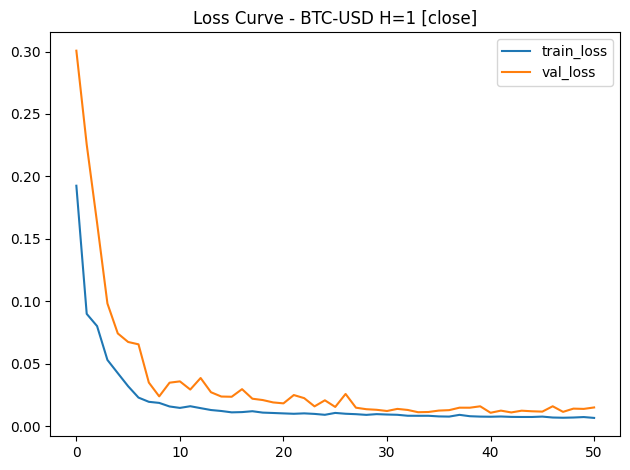

In [37]:
plt.figure()
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title(f"Loss Curve - {TICKER} H={H} [{MODE}]")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
yhat_test_s = model.predict(X_test).ravel()
yhat_test = y_scaler.inverse_transform(yhat_test_s.reshape(-1,1)).ravel()

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step


In [39]:
# yhat_test = model.predict(X_test).reshape(-1)

In [40]:
def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))

def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_pred - y_true)))

def mape(y_true, y_pred, eps=1e-8):
    return float(np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100)

metrics = {
    "ticker": TICKER,
    "mode": MODE,
    "H": H,
    "LOOKBACK": LOOKBACK,
    "test_RMSE": rmse(y_test, yhat_test),
    "test_MAE": mae(y_test, yhat_test),
    "test_MAPE": mape(y_test, yhat_test),
}

metrics

{'ticker': 'BTC-USD',
 'mode': 'close',
 'H': 1,
 'LOOKBACK': 60,
 'test_RMSE': 12738.59771498243,
 'test_MAE': 10685.956547448395,
 'test_MAPE': 10.10449085658149}

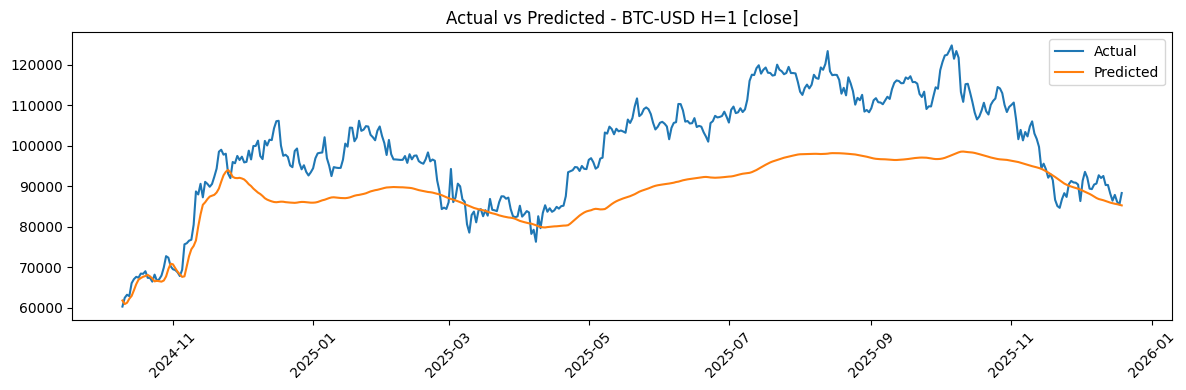

In [41]:
plt.figure(figsize=(12,4))
plt.plot(test_dates, y_test, label="Actual")
plt.plot(test_dates, yhat_test, label="Predicted")
plt.title(f"Actual vs Predicted - {TICKER} H={H} [{MODE}]")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
model_path = os.path.join(MODEL_DIR, f"{TICKER}_H{H}_L{LOOKBACK}_{MODE}.keras")
metrics_path = os.path.join(MODEL_DIR, f"metrics_{TICKER}_H{H}_L{LOOKBACK}_{MODE}.csv")

model.save(model_path)
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

print("Saved model  :", model_path)
print("Saved metrics:", metrics_path)

Saved model  : ../models/attention_lstm\BTC-USD_H1_L60_close.keras
Saved metrics: ../models/attention_lstm\metrics_BTC-USD_H1_L60_close.csv


In [43]:
loss_fig = os.path.join(FIG_DIR, f"loss_{TICKER}_H{H}_L{LOOKBACK}_{MODE}.png")
pred_fig = os.path.join(FIG_DIR, f"pred_{TICKER}_H{H}_L{LOOKBACK}_{MODE}.png")

# loss
plt.figure()
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title(f"Loss Curve - {TICKER} H={H} [{MODE}]")
plt.legend()
plt.tight_layout()
plt.savefig(loss_fig, dpi=150)
plt.close()

# prediction
plt.figure(figsize=(12,4))
plt.plot(test_dates, y_test, label="Actual")
plt.plot(test_dates, yhat_test, label="Predicted")
plt.title(f"Actual vs Predicted - {TICKER} H={H} [{MODE}]")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(pred_fig, dpi=150)
plt.close()

print("Saved figures:", loss_fig, pred_fig)

Saved figures: ../figures\loss_BTC-USD_H1_L60_close.png ../figures\pred_BTC-USD_H1_L60_close.png
